In [1]:
!pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable
  Using cached opencv_python-4.7.0.68-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (61.8 MB)


In [1]:
path = "images/"

# Part 1 - Denoising

## 1.1 Gaussian Noise 

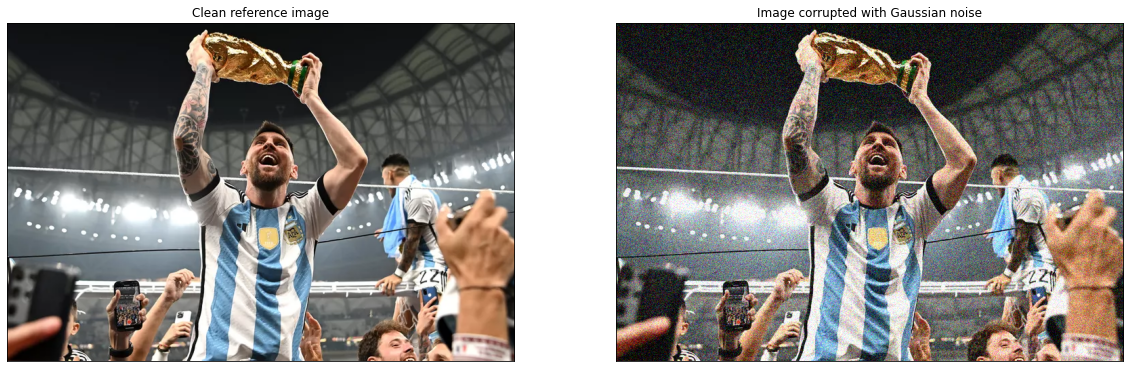

In [2]:
import cv2
import matplotlib.pyplot as plt
import math
import numpy as np


def show_sbs(img1, img2, t1, t2, cmap=None):
    "Show two images side by side"

    fig, ax = plt.subplots(1, 2, figsize=(20, 10))

    # remove ticks and labels
    ax[0].tick_params(
        left=False, right=False, labelleft=False, labelbottom=False, bottom=False
    )
    ax[1].tick_params(
        left=False, right=False, labelleft=False, labelbottom=False, bottom=False
    )

    # show both images
    ax[0].imshow(img1, cmap=cmap)
    ax[0].title.set_text(t1)
    ax[1].imshow(img2, cmap=cmap)
    ax[1].title.set_text(t2)
    plt.show()


noisy = cv2.imread(path + "messi-gaussian.png")  # in BGR
clean = cv2.imread(path + "messi.png")  # in BGR

# OpenCV2 reads images in BGR format but matplotlib displays them in RGB
# Here, we convert to RGB for displaying
noisy = cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB)
clean = cv2.cvtColor(clean, cv2.COLOR_BGR2RGB)

show_sbs(clean, noisy, "Clean reference image", "Image corrupted with Gaussian noise")


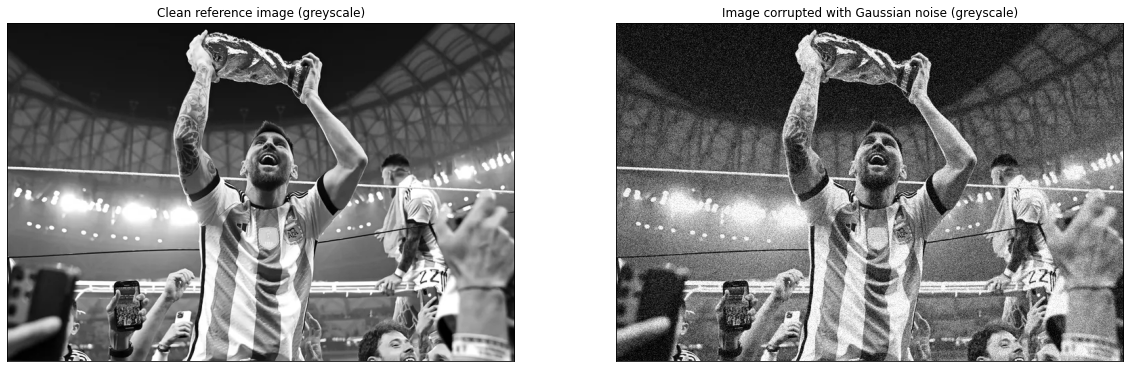

In [3]:
clean = cv2.cvtColor(clean, cv2.COLOR_RGB2GRAY)  # convert to greyscale
noisy = cv2.cvtColor(noisy, cv2.COLOR_RGB2GRAY)  # convert to greyscale

show_sbs(
    clean,
    noisy,
    "Clean reference image (greyscale)",
    "Image corrupted with Gaussian noise (greyscale)",
    cmap="gray",
)


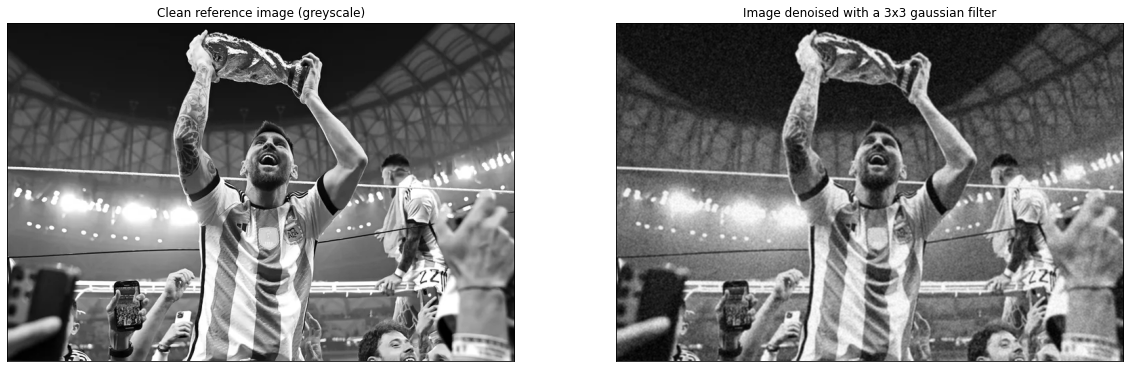

In [4]:
flt_dim = 3
flt_variance = 3


# our own implementation
def gaussian_kernel(size, variance):
    "Create a 2d gaussian kernel with given size and variance"
    g = np.linspace(-0.5 * (size - 1), 0.5 * (size - 1), size)
    g = np.exp(-0.5 * np.square(g) / variance)
    g = np.einsum("i,j->ij", g, g)
    g = g / np.sum(g)
    return g


gaussian_kernel2d = gaussian_kernel(3, 3)

# # TODO: question: Should we take sqrt of variance to get std?
# gaussian_kernel1d = cv2.getGaussianKernel(3, math.sqrt(flt_variance))

# # Multiply 1d filter by uts transose to get 2d filter
# gaussian_kernel2d = np.multiply(gaussian_kernel1d.T, gaussian_kernel1d)


# convolve the image with the computed kernel
filtered_gaussian = cv2.filter2D(src=noisy, ddepth=-1, kernel=gaussian_kernel2d)
show_sbs(
    clean,
    filtered_gaussian,
    "Clean reference image (greyscale)",
    "Image denoised with a 3x3 gaussian filter",
    cmap="gray",
)


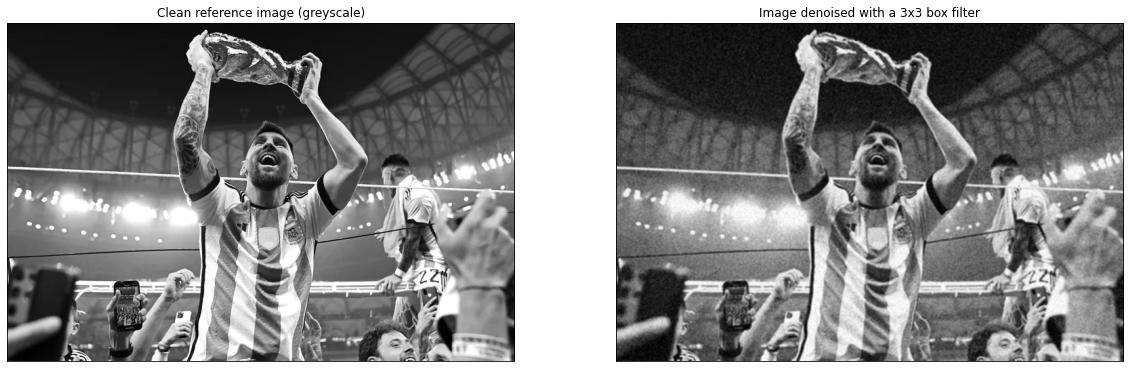

In [5]:
# manually create the box kernel
box_kernel = np.array([[1, 1, 1], [1, 1, 1], [1, 1, 1]]) / (flt_dim**2)

# convolve the image with the computed kernel
filtered_box = cv2.filter2D(src=noisy, ddepth=-1, kernel=box_kernel)
show_sbs(
    clean,
    filtered_box,
    "Clean reference image (greyscale)",
    "Image denoised with a 3x3 box filter",
    cmap="gray",
)


In [6]:
PSNRs = {
    "unfiltered": cv2.PSNR(clean, noisy),
    "gaussian filtering": cv2.PSNR(clean, filtered_gaussian),
    "box filtering": cv2.PSNR(clean, filtered_box),
}

print("PSNRs: ")
for key, value in PSNRs.items():
    print(f"\t{key}: {value}")

print("\n", max(PSNRs, key=PSNRs.get) + " achieves the highest PSNR")


PSNRs: 
	unfiltered: 22.41024067947022
	gaussian filtering: 26.29479603624449
	box filtering: 26.048375281082606

 gaussian filtering achieves the highest PSNR


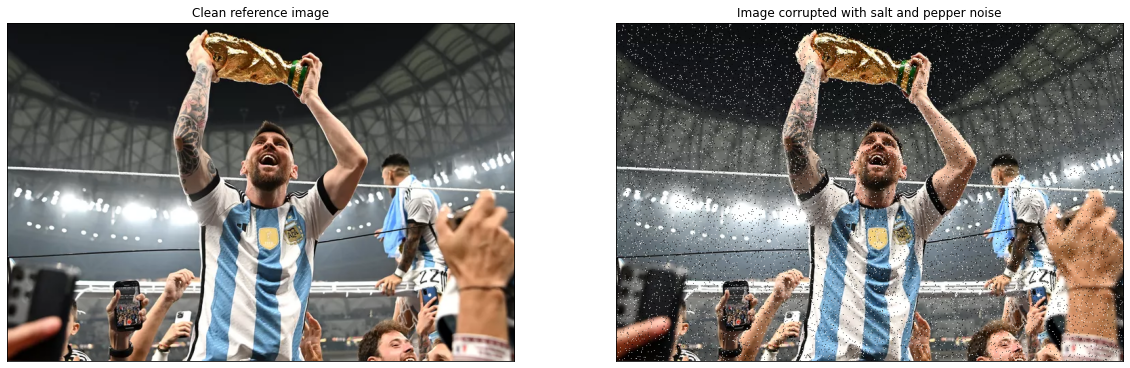

In [7]:
noisy = cv2.imread(path + "salt-and-pepper-messi2.png")  # in BGR
clean = cv2.imread(path + "messi.png")  # in BGR

# OpenCV2 reads images in BGR format but matplotlib displays them in RGB
# Here, we convert to RGB for displaying
clean = cv2.cvtColor(clean, cv2.COLOR_BGR2RGB)
noisy = cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB)

show_sbs(clean, noisy, "Clean reference image", "Image corrupted with salt and pepper noise")


## 1.2 Salt and Pepper Noise

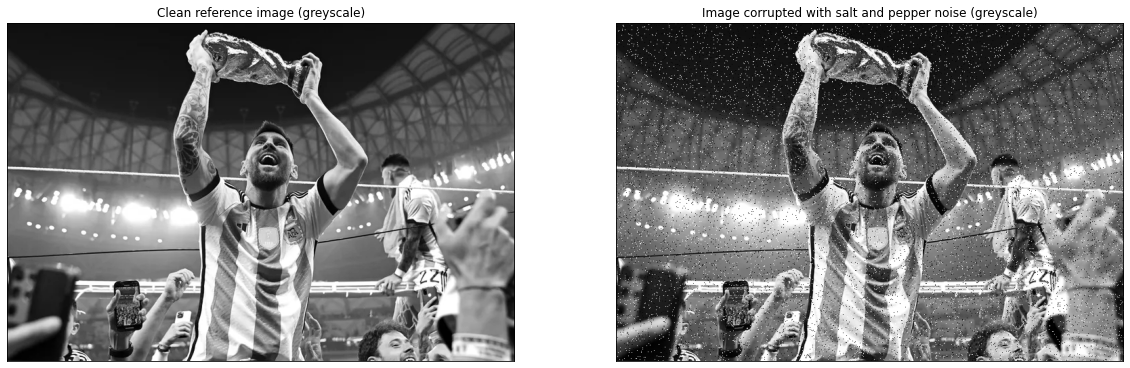

In [8]:
noisy = cv2.cvtColor(noisy, cv2.COLOR_RGB2GRAY)  # convert to greyscale
clean = cv2.cvtColor(clean, cv2.COLOR_RGB2GRAY)  # convert to greyscale

show_sbs(
    clean,
    noisy,
    "Clean reference image (greyscale)",
    "Image corrupted with salt and pepper noise (greyscale)",
    cmap="gray",
)

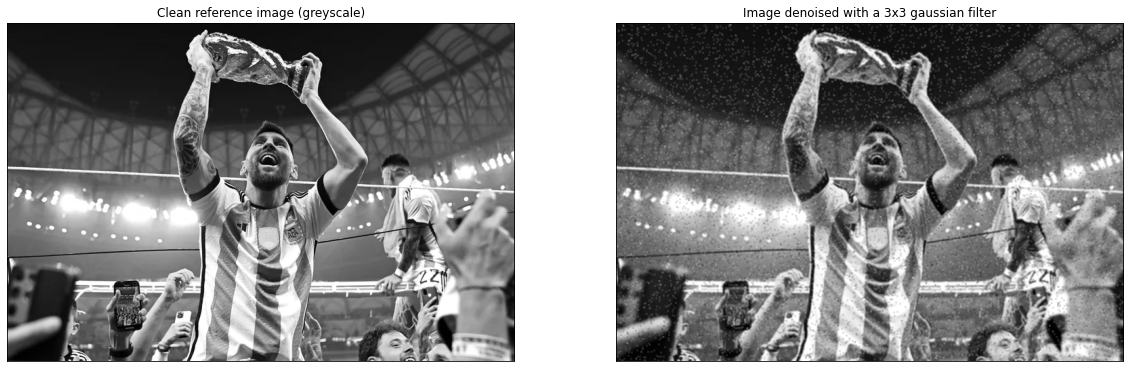

In [9]:
# convolve the image with the computed kernel
filtered_gaussian = cv2.filter2D(src=noisy, ddepth=-1, kernel=gaussian_kernel2d)
show_sbs(
    clean,
    filtered_gaussian,
    "Clean reference image (greyscale)",
    "Image denoised with a 3x3 gaussian filter",
    cmap="gray",
)

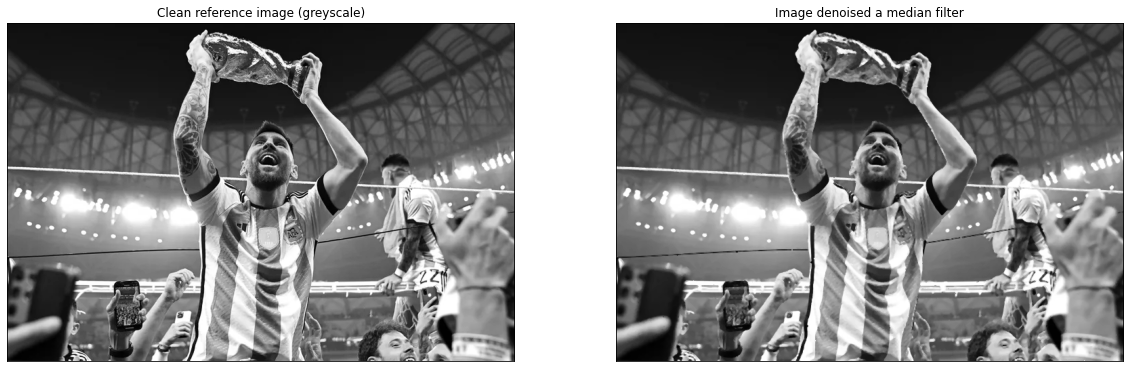

In [53]:
# Implement median filtering
def median_filtering(img, kernel_size, padding=False):
    # if padding is True, we add padding on all 4 sides of the image
    # the padding size is the kernel size//2
    # this allows for filtering values near the corners/edges of the image
    pad = 0
    flt_img = np.zeros_like(img)
    half_kernel = kernel_size // 2
    if padding:
        pad = half_kernel
        img = np.pad(img, pad, mode="edge")

    # we don't iterate through the padding pixels we added
    for row in range(pad, img.shape[0] - pad):
        for col in range(pad, img.shape[1] - pad):
            flt_img[row - pad, col - pad] = np.median(
                img[
                    row - half_kernel : row + half_kernel + 1,
                    col - half_kernel : col + half_kernel + 1,
                ].flatten()
            )

    return flt_img


median_filtering(noisy, 3, padding=True)

filtered_median = median_filtering(noisy, flt_dim, padding=True)
show_sbs(
    clean,
    filtered_median,
    "Clean reference image (greyscale)",
    "Image denoised a median filter",
    cmap="gray",
)


In [54]:
PSNRs = {
    "unfiltered": cv2.PSNR(clean, noisy),
    "gaussian filtering": cv2.PSNR(clean, filtered_gaussian),
    "median filtering": cv2.PSNR(clean, filtered_median),
}

print("PSNRs: ")
for key, value in PSNRs.items():
    print(f"\t{key}: {value}")

print("\n", max(PSNRs, key=PSNRs.get) + " achieves the highest PSNR")


PSNRs: 
	unfiltered: 17.939198281102204
	gaussian filtering: 24.54206660268435
	median filtering: 29.899863383529215

 median filtering achieves the highest PSNR
